# Browning & freshening of the two DBO2 inflow branches — self-contained 2×2 figure

Run top to bottom. Nothing streams from NASA; everything reads two caches written by earlier
notebooks in this folder:

| cache | written by | holds |
|---|---|---|
| `oisss_west_cache/monthly_sss_ease2west_gauss.nc` | `09_bering-and-anadyr-caches.ipynb` | monthly OISSS SSS on the EASE-2 *west* grid |
| `bering_full_cache/adg443/*.nc` | `09_bering-and-anadyr-caches.ipynb` | MODIS 8-day a$_{dg}$(443), lat/lon |

### What it makes

A 2×2 figure: per-pixel a$_{dg}$(443) and SSS trend maps (left) against box-mean anomaly series for
the two inflow branches (right).

**One cadence throughout.** Every panel is a Theil–Sen slope on **month-of-year anomalies** with an
AR(1)-corrected Mann–Kendall test. The a$_{dg}$ product arrives as 8-day composites and is resampled
to monthly means first — both for the map and for the box series — so the four panels are the same
construction and the caption needs no exceptions. (The original notebook fitted the map with OLS on
8-day anomalies and the box series on 8-day anomalies; both were changed.)

**Why monthly and not 8-day.** Theil–Sen is the median of all pairwise slopes, so it is quadratic in
sample size: at 8-day cadence that is ~6×10⁵ pairs per pixel against ~4.6×10³ at monthly. Monthly is
also the native cadence of the OISSS product, so the two variables end up directly comparable.

### The two boxes

*Anadyr side* = **Anadyr Strait** (63.3–64.7 °N, 173.5–170.8 °W) — the western inflow pathway, ~600 km
downstream of the Anadyr River mouth. *Yukon side* = **box C** (62.4–64.4 °N, 169.0–164.0 °W), the
Chirikov Basin water fed by the Yukon outflow. DBO1 and DBO2 are drawn for orientation only and are
not averaged.

## 1. Imports, paths, geometry

In [1]:
import time as _time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.gridspec as gridspec
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from pyresample import AreaDefinition
from scipy.stats import theilslopes, kendalltau, norm
warnings.filterwarnings("ignore", category=RuntimeWarning)

# --- caches: set explicitly, or leave None and they are searched for ---------------------
OISSS_CACHE = None      # e.g. "~/source-of-browning/oisss_west_cache/monthly_sss_ease2west_gauss.nc"
MODIS_CACHE = None      # e.g. "~/source-of-browning/bering_full_cache/adg443"

_ROOTS = [Path.cwd(), Path.cwd() / "source-of-browning", Path.cwd().parent,
          Path("ADD_YOUR_PATH"), Path("ADD_YOUR_PATH"),  # add your path
          Path.home(), Path.home() / "ADD_YOUR_PATH" / "source-of-browning"]  # add your path

def _find(rel, want_dir=False):
    for r in dict.fromkeys(_ROOTS):
        p = r / rel
        if (p.is_dir() if want_dir else p.exists()):
            return p
    return None

OISSS_CACHE = (Path(OISSS_CACHE) if OISSS_CACHE else
               _find("oisss_west_cache/monthly_sss_ease2west_gauss.nc"))
MODIS_CACHE = (Path(MODIS_CACHE) if MODIS_CACHE else
               _find("bering_full_cache/adg443", want_dir=True))
if OISSS_CACHE is None or MODIS_CACHE is None:
    print("searched:", *[str(r) for r in dict.fromkeys(_ROOTS)], sep="\n  ")
    raise FileNotFoundError(f"OISSS: {OISSS_CACHE}\nMODIS: {MODIS_CACHE}\n"
                            "set OISSS_CACHE / MODIS_CACHE explicitly")
SYNOUT = Path("synthesis_output"); SYNOUT.mkdir(exist_ok=True)
print(f"OISSS  {OISSS_CACHE}\nMODIS  {MODIS_CACHE}\nout    {SYNOUT}/")

SEASON = [6, 7, 8, 9]                       # June-September everywhere in this notebook
MIN_N_PX  = 20                              # monthly Jun-Sep anomalies needed per pixel
STRIDE_PX = 1                               # raise to 2-3 if the pixel fit is too slow

REGIONS = {   # lat0, lat1, lon360_0, lon360_1, colour
    "AnadyrInner":  (63.6, 65.0, 176.5, 180.5, "#D55E00"),
    "AnadyrOuter":  (61.8, 63.6, 174.0, 179.5, "#56B4E9"),
    "AnadyrStrait": (63.3, 64.7, 186.5, 189.2, "#999933"),
    "DBO1":         (61.85, 63.77, 184.2, 187.8, "#AA4499"),
    "DBO2":         (64.48, 65.11, 189.1, 192.2, "#CC79A7"),
    "boxC":         (62.4, 64.4, 191.0, 196.0, "#009E73"),
}
WEST_KEYS, EAST_KEY = ["AnadyrStrait"], "boxC"   # Strait only: the pathway sentinel feeding DBO2 west
WEST_C, EAST_C = "#6A51A3", "#E69F00"            # purple / golden yellow (CVD-safe pair)

# EASE-2 west grid geometry (verbatim from oisss-anadyr-freshening)
dbo_area_west = AreaDefinition(
    "ease2_north_dbo_west_4km", "dbo_area + 100 cols east", "EPSG:6931",
    {"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0,
     "datum": "WGS84", "units": "m"},
    1006, 845, (-3_624_000, 992_000, 400_000, 4_372_000))
CELL = 4000.0
lons2d, lats2d = dbo_area_west.get_lonlats()
lon360_2d = lons2d % 360
masks_full = {n: ((lats2d >= a0) & (lats2d <= a1) & (lon360_2d >= o0) & (lon360_2d <= o1))
              for n, (a0, a1, o0, o1, _c) in REGIONS.items()}
union = np.zeros_like(lons2d, bool)
for m in masks_full.values():
    union |= m
jj, ii = np.where(union); PAD = 15
j0, j1 = max(jj.min() - PAD, 0), min(jj.max() + PAD, 844)
i0, i1 = max(ii.min() - PAD, 0), min(ii.max() + PAD, 1005)
xv, yv = dbo_area_west.get_proj_vectors()
WORK_EXT = (xv[i0] - CELL/2, yv[j1] - CELL/2, xv[i1] + CELL/2, yv[j0] + CELL/2)
masks = {n: m[j0:j1+1, i0:i1+1] for n, m in masks_full.items()}
print("geometry ready; work window", j1-j0+1, "x", i1-i0+1)

OISSS  ~/oisss_west_cache/monthly_sss_ease2west_gauss.nc
MODIS  ~/bering_full_cache/adg443
out    synthesis_output/
geometry ready; work window 135 x 321


## 2. Trend helpers — Theil–Sen + AR(1)-corrected Mann–Kendall

In [2]:
def _lag1(r):
    a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def ts_mk_ar1_xy(x, y, minn=12):
    """Theil-Sen slope (per unit x) + AR(1)-corrected Mann-Kendall p."""
    v = np.isfinite(x) & np.isfinite(y)
    x, y = np.asarray(x, float)[v], np.asarray(y, float)[v]
    if len(x) < minn:
        return dict(slope=np.nan, intercept=np.nan, p=np.nan, n=len(x))
    sl, ic, *_ = theilslopes(y, x, 0.95)
    b1, b0 = np.polyfit(x, y, 1)
    phi = _lag1(y - (b1 * x + b0))
    n = len(x); ne = n * (1 - phi) / (1 + phi) if abs(phi) < 1 else n
    tau, _ = kendalltau(x, y)
    p = np.nan
    if ne > 4:
        z = tau / np.sqrt(2 * (2 * ne + 5) / (9 * ne * (ne - 1)))
        p = 2 * (1 - norm.cdf(abs(z)))
    return dict(slope=sl, intercept=ic, p=p, n=n)

def pixel_trend(arr, xdec, min_n):
    """Theil-Sen slope PER DECADE + MK-AR1 p for every pixel of arr(time, y, x)."""
    sl = np.full(arr.shape[1:], np.nan); pa = np.full(arr.shape[1:], np.nan)
    jj_, ii_ = np.where(np.isfinite(arr).sum(axis=0) >= min_n)
    t0 = _time.time()
    for k, (j, i) in enumerate(zip(jj_, ii_)):
        r = ts_mk_ar1_xy(xdec, arr[:, j, i], minn=min_n)
        sl[j, i] = r["slope"] * 10
        pa[j, i] = r["p"]
        if k % 20000 == 0 and k:
            print(f"   {k:,}/{len(jj_):,} px ({(_time.time()-t0)/60:.1f} min)", end="\r")
    print(f"   fit {len(jj_):,} pixels in {(_time.time()-t0)/60:.1f} min")
    return sl, pa

def month_of_year_anom(sub, tsub):
    """Per-pixel (or per-point) month-of-year anomaly over the SEASON months."""
    anom = np.full_like(sub, np.nan, dtype=float)
    for mth in SEASON:
        k = tsub.month == mth
        anom[k] = sub[k] - np.nanmean(sub[k], axis=0)
    return anom

print("helpers ready")

helpers ready


## 3. Salinity — per-pixel trend and box series

OISSS is already monthly, so this is the reference construction the other panels are matched to.

In [3]:
sss = xr.open_dataarray(OISSS_CACHE)
if sss.shape[1:] == (845, 1006):                     # full grid -> crop to the work window
    sss = sss.isel(y=slice(j0, j1 + 1), x=slice(i0, i1 + 1))
assert sss.shape[1:] == masks["boxC"].shape, f"SSS grid {sss.shape[1:]} != {masks['boxC'].shape}"

tt   = pd.to_datetime(sss.time.values)
sel  = np.isin(tt.month, SEASON)
sub  = sss.values[sel].astype(float)
tsub = tt[sel]
anom = month_of_year_anom(sub, tsub)
xdec = (tsub.year + (tsub.dayofyear - 1) / 365.25).values.astype(float)

print(f"SSS: {len(tt)} months {tt[0]:%Y-%m} -> {tt[-1]:%Y-%m}; fitting pixels...")
sl_sss, pa_sss = pixel_trend(anom, xdec, min_n=20)
print(f"   {np.isfinite(sl_sss).sum():,} pixels fitted, "
      f"{int(np.nansum(pa_sss < 0.05)):,} significant (p<0.05)")

W_MASK, E_MASK = masks[WEST_KEYS[0]], masks[EAST_KEY]

def sss_region_monthly_anom(mask):
    ser = sss.where(xr.DataArray(mask, dims=("y", "x"))).mean(("y", "x"), skipna=True)
    s = pd.Series(np.asarray(ser.values, float), index=pd.to_datetime(sss.time.values))
    return s - s.groupby(s.index.month).transform("mean")

sss_series = {"West (Anadyr Strait)": sss_region_monthly_anom(W_MASK),
              "East (box C)":         sss_region_monthly_anom(E_MASK)}
print("sss_series built")

SSS: 176 months 2011-09 -> 2026-04; fitting pixels...
   fit 25,403 pixels in 0.7 min
   25,403 pixels fitted, 9,484 significant (p<0.05)
sss_series built


## 4. a$_{dg}$(443) — per-pixel trend and box series, both on monthly means

The 8-day composites are resampled to monthly means **before** anything else, so the map and the box
series use the same construction as the salinity panels above.

In [4]:
def _open_adg():
    ds = xr.open_mfdataset(sorted(MODIS_CACHE.glob("*.nc")), combine="nested",
                           concat_dim="time", engine="h5netcdf", data_vars="minimal",
                           coords="minimal", compat="override")
    da = ds["adg443"].sortby("time")
    return ds, da

# ---- (a) per-pixel map -----------------------------------------------------------------
ds, daw = _open_adg()
lat_desc = daw.lat.values[0] > daw.lat.values[-1]
daw = daw.sel(lat=slice(66.5, 59.5) if lat_desc else slice(59.5, 66.5),
              lon=slice(166.0, 199.0))
mon = daw.resample(time="1MS").mean().load()          # resample BEFORE load: ~12x less memory
ds.close(); del daw

tt_a   = pd.to_datetime(mon.time.values)
sel_a  = np.isin(tt_a.month, SEASON)
sub_a  = mon.values[sel_a].astype(float)
tsub_a = tt_a[sel_a]
PXLON, PXLAT = mon.lon.values, mon.lat.values
del mon

anom_a = month_of_year_anom(sub_a, tsub_a)
xdec_a = (tsub_a.year + (tsub_a.dayofyear - 1) / 365.25).values.astype(float)
print(f"adg: {len(tsub_a)} monthly Jun-Sep steps "
      f"{tsub_a[0]:%Y-%m} -> {tsub_a[-1]:%Y-%m}; fitting pixels...")
del sub_a

if STRIDE_PX > 1:
    S = STRIDE_PX
    _sl, _pa = pixel_trend(anom_a[:, ::S, ::S], xdec_a, min_n=MIN_N_PX)
    up = lambda z: np.kron(z, np.ones((S, S)))[:len(PXLAT), :len(PXLON)]
    sl_px, pa_px = up(_sl), up(_pa)
else:
    sl_px, pa_px = pixel_trend(anom_a, xdec_a, min_n=MIN_N_PX)
print(f"   {np.isfinite(sl_px).sum():,} pixels fitted, "
      f"{int(np.nansum(pa_px < 0.05)):,} significant (p<0.05)")
print("   |slope| percentiles [50, 90, 98]:",
      np.round(np.nanpercentile(np.abs(sl_px), [50, 90, 98]), 5))

# ---- (b) box-mean series ---------------------------------------------------------------
def monthly_box_anom(lat_rng, lon_rngs):
    """Box-mean 8-day series -> monthly means -> 12-slot month-of-year anomaly."""
    ds_, da = _open_adg()
    da = da.sel(lat=slice(lat_rng[1], lat_rng[0]) if lat_desc else slice(*lat_rng)).load()
    ds_.close()
    LO = da.lon.values
    mask = np.zeros(LO.shape, bool)
    for lo0, lo1 in lon_rngs:
        mask |= (LO >= lo0) & (LO <= lo1)
    s = da.isel(lon=np.where(mask)[0]).mean(("lat", "lon"), skipna=True)
    ser = pd.Series(s.values.astype(float), index=pd.to_datetime(s.time.values))
    m_ = ser.resample("MS").mean()
    moy = m_.index.month.values
    clim = np.full(13, np.nan)
    for mm in range(1, 13):
        k = (moy == mm) & np.isfinite(m_.values)
        if k.sum() >= 5:
            clim[mm] = np.nanmean(m_.values[k])
    return m_ - clim[moy]

west_lat  = (min(REGIONS[k][0] for k in WEST_KEYS), max(REGIONS[k][1] for k in WEST_KEYS))
west_lons = [(REGIONS[k][2], REGIONS[k][3]) for k in WEST_KEYS]
east_lat  = (REGIONS[EAST_KEY][0], REGIONS[EAST_KEY][1])
east_lons = [(REGIONS[EAST_KEY][2], REGIONS[EAST_KEY][3])]
series = {"West (Anadyr Strait)": monthly_box_anom(west_lat, west_lons),
          "East (box C)":         monthly_box_anom(east_lat, east_lons)}
print("series built")

adg: 95 monthly Jun-Sep steps 2002-07 -> 2025-09; fitting pixels...
   fit 71,300 pixels in 2.0 min
   71,300 pixels fitted, 10,980 significant (p<0.05)
   |slope| percentiles [50, 90, 98]: [0.00383 0.01465 0.06112]
series built


## 5. Map labels

In [5]:
BOX_LABELS = {   # region -> (label text, lon360, lat, ha)
    "AnadyrInner":  ("Inner",  178.5, 65.18, "center"),
    "AnadyrOuter":  ("Outer",  175.6, 61.52, "center"),
    "AnadyrStrait": ("Strait", 186.2, 64.95, "center"),
    "DBO1":         ("DBO 1",  185.9, 61.55, "center"),
    "DBO2":         ("DBO 2",  192.6, 65.35, "left"),
    "boxC":         ("C",      193.5, 62.12, "center"),
}
RIVERS = {   # name -> (lon360, lat, label_dy)
    "Yukon R.":  (195.5, 62.75, -0.32),
    "Anadyr R.": (177.45, 64.80, +0.28),
}
PLACES = [("Gulf of\nAnadyr", 179.8, 62.05), ("Chirikov", 190.5, 64.05),
          ("Bering Strait", 190.0, 65.9)]
SKIP_PLACES = {"Chirikov"}          # crowds the Yukon-side box
print("labels ready")

labels ready


## 6. The figure

Only DBO1 and DBO2 are outlined, to declutter. Every text annotation carries a white halo — place
names had none originally, so "Bering Strait" vanished over the dark a$_{dg}$ field.

saved -> synthesis_output/fig_story_2x2_monthly.png and .pdf


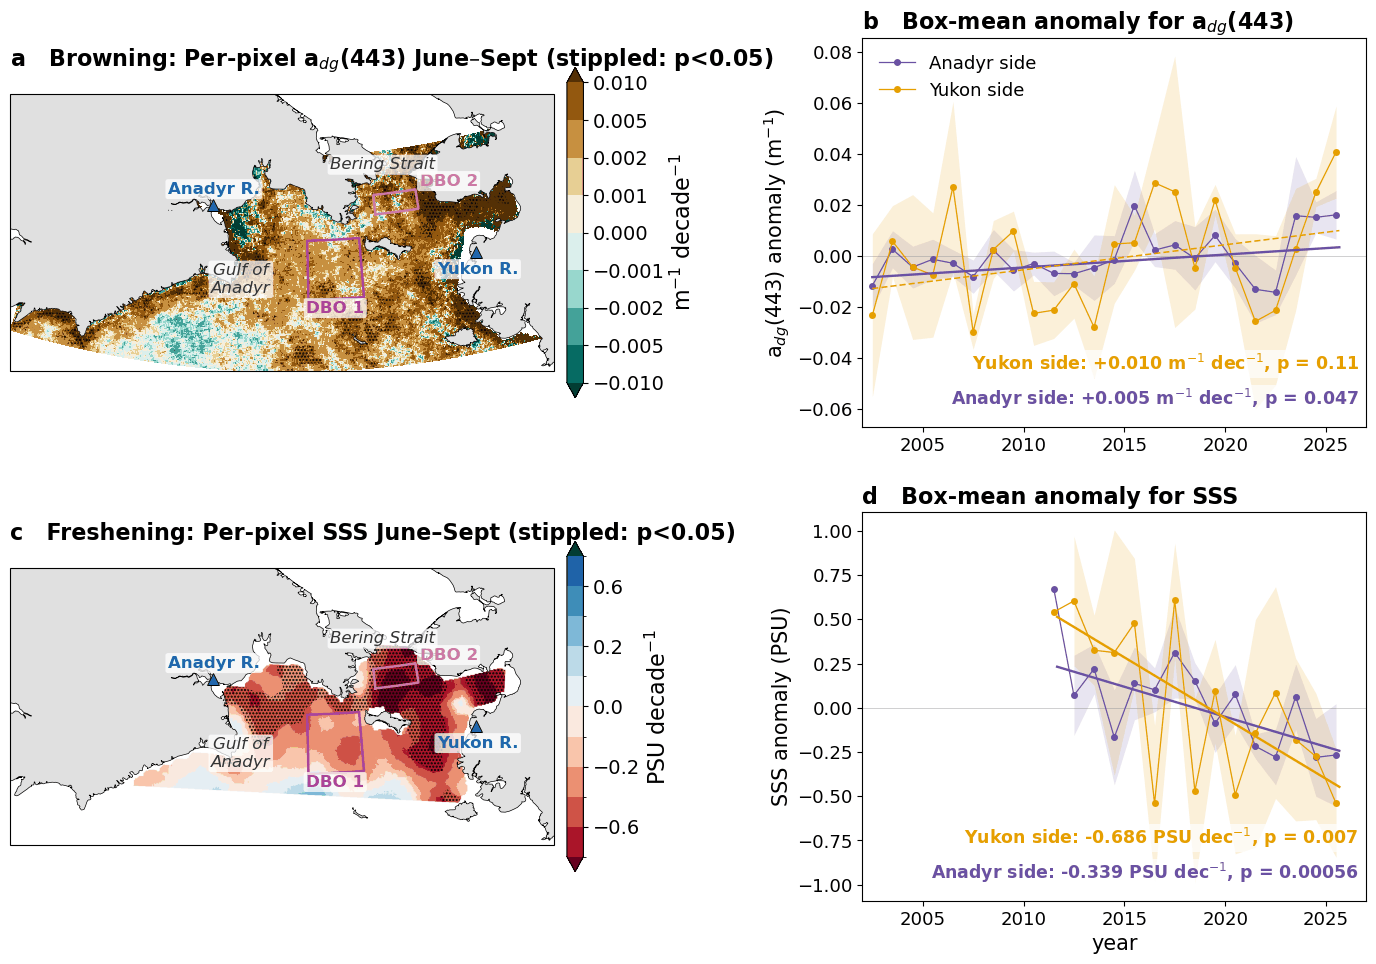

In [6]:
# FONT SCALE — panel titles, axis labels, ticks, colorbars.
FS_PANEL, FS_CB, FS_CBT, FS_AXL, FS_TICK, FS_ANN, FS_MAPLBL, FS_LEG = 16, 16, 14, 15, 13, 12.5, 12, 13

SEASON_LBL = "June–Sept"
DISPLAY = {"West (Anadyr Strait)": "Anadyr side", "East (box C)": "Yukon side"}
HALO = dict(facecolor="white", edgecolor="none", alpha=0.75, boxstyle="round,pad=0.15")


def annotate_map_min(ax):
    """DBO1 + DBO2 boxes only; river markers and place names kept."""
    for name in ("DBO1", "DBO2"):
        a0, a1, o0, o1, c = REGIONS[name]
        lo = np.concatenate([np.linspace(o0, o1, 30), np.full(30, o1),
                             np.linspace(o1, o0, 30), np.full(30, o0)])
        la = np.concatenate([np.full(30, a0), np.linspace(a0, a1, 30),
                             np.full(30, a1), np.linspace(a1, a0, 30)])
        ax.plot(lo, la, color=c, lw=1.8, transform=ccrs.PlateCarree(), zorder=5)
        txt, tlo, tla, ha = BOX_LABELS[name]
        ax.text(tlo, tla, txt, transform=ccrs.PlateCarree(), fontsize=FS_MAPLBL,
                fontweight="bold", color=c, ha=ha, va="center", zorder=6, bbox=HALO)
    for rname, (rlo, rla, dy) in RIVERS.items():
        ax.plot(rlo, rla, marker="^", ms=9, color="#2166AC", mec="black", mew=0.6,
                ls="none", transform=ccrs.PlateCarree(), zorder=7)
        ax.text(rlo, rla + dy, rname, transform=ccrs.PlateCarree(), fontsize=FS_MAPLBL,
                fontweight="bold", color="#2166AC", ha="center",
                va="top" if dy < 0 else "bottom", zorder=7, bbox=HALO)
    for txt, plo, pla in PLACES:
        if txt in SKIP_PLACES:
            continue
        ax.text(plo, pla, txt, transform=ccrs.PlateCarree(), fontsize=FS_MAPLBL,
                color="#333333", ha="center", style="italic", zorder=6, bbox=HALO)


data_crs = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=0)
disp     = ccrs.LambertAzimuthalEqualArea(central_latitude=90, central_longitude=-177)
fig = plt.figure(figsize=(17.5, 11.2))
gs = gridspec.GridSpec(2, 2, width_ratios=[1.3, 1], hspace=0.22, wspace=0.34)

# ---- (a) adg trend map -----------------------------------------------------------------
ax = fig.add_subplot(gs[0, 0], projection=disp)
ax.set_extent([166, 199, 59.5, 67.5], crs=ccrs.PlateCarree())
levels_a = [-0.01, -0.005, -0.002, -0.001, 0, 0.001, 0.002, 0.005, 0.01]
cmap_a = plt.get_cmap("BrBG_r").copy(); cmap_a.set_bad("#ececec", 0)
im_a = ax.pcolormesh(PXLON, PXLAT, sl_px, transform=ccrs.PlateCarree(), cmap=cmap_a,
                     norm=mcolors.BoundaryNorm(levels_a, cmap_a.N, extend="both"), zorder=1)
LOp, LAp = np.meshgrid(PXLON, PXLAT)
ax.contourf(LOp, LAp, np.where(np.isfinite(pa_px) & (pa_px < 0.05), 1.0, np.nan),
            levels=[0.5, 1.5], colors="none", hatches=["....."],
            transform=ccrs.PlateCarree(), zorder=4)
ax.add_feature(cfeature.LAND, facecolor="0.88", zorder=2); ax.coastlines(lw=0.5, zorder=3)
annotate_map_min(ax)
# pad lifts the title clear of the colorbar's top tick label, which sits at the axes top
ax.set_title(f"a   Browning: Per-pixel a$_{{dg}}$(443) {SEASON_LBL} (stippled: p<0.05)",
             loc="left", fontsize=FS_PANEL, fontweight="bold", pad=20)
_cb = fig.colorbar(im_a, ax=ax, shrink=0.85, pad=0.02)
_cb.set_label("m$^{-1}$ decade$^{-1}$", fontsize=FS_CB); _cb.ax.tick_params(labelsize=FS_CBT)

# ---- (c) SSS trend map -----------------------------------------------------------------
ax = fig.add_subplot(gs[1, 0], projection=disp)
ax.set_extent([166, 199, 59.5, 67.5], crs=ccrs.PlateCarree())
levels_s = [-1.0, -0.6, -0.4, -0.2, -0.1, 0, 0.1, 0.2, 0.4, 0.6, 1.0]
cmap_s = plt.get_cmap("RdBu").copy(); cmap_s.set_bad("#ececec", 0)
wx0, wy0, wx1, wy1 = WORK_EXT
im_s = ax.imshow(sl_sss, origin="upper", extent=[wx0, wx1, wy0, wy1], transform=data_crs,
                 cmap=cmap_s, norm=mcolors.BoundaryNorm(levels_s, cmap_s.N, extend="both"),
                 zorder=1)
XX, YY = np.meshgrid(np.linspace(wx0 + CELL/2, wx1 - CELL/2, sl_sss.shape[1]),
                     np.linspace(wy1 - CELL/2, wy0 + CELL/2, sl_sss.shape[0]))
ax.contourf(XX, YY, np.where(np.isfinite(pa_sss) & (pa_sss < 0.05), 1.0, np.nan),
            levels=[0.5, 1.5], colors="none", hatches=["....."],
            transform=data_crs, zorder=4)
ax.add_feature(cfeature.LAND, facecolor="0.88", zorder=2); ax.coastlines(lw=0.5, zorder=3)
annotate_map_min(ax)
ax.set_title(f"c   Freshening: Per-pixel SSS {SEASON_LBL} (stippled: p<0.05)",
             loc="left", fontsize=FS_PANEL, fontweight="bold", pad=20)
_cb = fig.colorbar(im_s, ax=ax, shrink=0.85, pad=0.02)
_cb.set_label("PSU decade$^{-1}$", fontsize=FS_CB); _cb.ax.tick_params(labelsize=FS_CBT)

# ---- (b, d) box-mean series ------------------------------------------------------------
for row, (dat, ylab, su, ttl) in enumerate([
        (series, "a$_{dg}$(443) anomaly (m$^{-1}$)", "m$^{-1}$ dec$^{-1}$",
         "b   Box-mean anomaly for a$_{dg}$(443)"),
        (sss_series, "SSS anomaly (PSU)", "PSU dec$^{-1}$",
         "d   Box-mean anomaly for SSS")]):
    ax = fig.add_subplot(gs[row, 1])
    ax.axhline(0, color="#c8c8c8", lw=0.6, zorder=1)
    for k, ((label, s0), col) in enumerate(zip(dat.items(), [WEST_C, EAST_C])):
        name = DISPLAY.get(label, label)
        s = s0[np.isin(s0.index.month, SEASON)]
        dec = s.index.year + (s.index.dayofyear - 1) / 365.25
        fit = ts_mk_ar1_xy(np.asarray(dec, float), s.values)
        g = s.groupby(s.index.year)
        m_, se_ = g.mean(), g.sem()
        ax.fill_between(m_.index + 0.5, m_ - 1.96*se_, m_ + 1.96*se_,
                        color=col, alpha=0.15, lw=0, zorder=2)
        ax.plot(m_.index + 0.5, m_.values, "o-", color=col, ms=4, lw=0.9,
                zorder=4, label=name)
        xx = np.array([np.nanmin(dec), np.nanmax(dec)])
        issig = np.isfinite(fit["p"]) and fit["p"] < 0.05
        ax.plot(xx, fit["intercept"] + fit["slope"]*xx, color=col,
                ls="-" if issig else (0, (4, 2)), lw=1.7 if issig else 1.1, zorder=5)
        ax.text(0.985, 0.04 + 0.09*k,
                f"{name}: {fit['slope']*10:+.3f} {su}, p = {fit['p']:.2g}",
                transform=ax.transAxes, ha="right", va="bottom", fontsize=FS_ANN,
                fontweight="bold", color=col,
                bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1.3))
    ax.set_ylabel(ylab, fontsize=FS_AXL)
    ax.set_title(ttl, loc="left", fontsize=FS_PANEL, fontweight="bold")
    ax.set_xlim(2002, 2027)
    ax.tick_params(labelsize=FS_TICK)
    if row == 0:
        ax.legend(fontsize=FS_LEG, frameon=False, loc="upper left")
    else:
        ax.set_xlabel("year", fontsize=FS_AXL)

for ext in ("png", "pdf"):
    fig.savefig(SYNOUT / f"fig_story_2x2_monthly.{ext}", dpi=200, bbox_inches="tight")
print(f"saved -> {SYNOUT/'fig_story_2x2_monthly'}.png and .pdf")
plt.show()

## 7. Numbers for the caption

In [ ]:
rows = []
for nm, dat, unit in [("adg443", series, "m^-1/dec"), ("SSS", sss_series, "PSU/dec")]:
    for label, s0 in dat.items():
        s = s0[np.isin(s0.index.month, SEASON)]
        dec = s.index.year + (s.index.dayofyear - 1) / 365.25
        f = ts_mk_ar1_xy(np.asarray(dec, float), s.values)
        rows.append((nm, DISPLAY.get(label, label), f["slope"]*10, f["p"], f["n"], unit))
tbl = pd.DataFrame(rows, columns=["var", "branch", "trend/decade", "p_AR1", "n_months", "unit"])
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
print(tbl.to_string(index=False))

# --- is the Anadyr River MOUTH different from the Strait? -------------------------------
jm = np.where(np.abs(PXLAT - 64.7) < 0.6)[0]
im_ = np.where((PXLON > 176.5) & (PXLON < 180.5))[0]
S_ = np.ix_(jm, im_)
fitmask = np.isfinite(sl_px[S_])
nv = np.isfinite(anom_a).sum(0)
print(f"\nAnadyr River mouth window: {fitmask.sum()} of {fitmask.size} pixels fitted")
if fitmask.any():
    print(f"  median slope    {np.median(sl_px[S_][fitmask]):+.5f} m^-1/dec")
    print(f"  fraction < 0    {np.mean(sl_px[S_][fitmask] < 0):.0%}")
    print(f"  fraction p<0.05 {np.mean(pa_px[S_][fitmask] < 0.05):.0%}")
    print(f"  valid months    median {np.median(nv[S_][fitmask]):.0f} of {anom_a.shape[0]}")
    print("  (fraction p<0.05 near 5% = no trend; the green is noise about zero)")

---

# Part B — Fig. S14: DBO 2 freshening, west vs east flank

*This part was a separate notebook before the repository was consolidated; it starts from its own imports and configuration, so it can be run on its own after the sections above.*

# East vs west, condensed: three synthesis figures

Replaces the per-month / per-region panel walls with three figures that carry the finding:

1. **SSS trend map, June–September pooled** (OISSS, EASE-2 west grid) — one map showing
   freshening concentrated on the eastern corridor/Chirikov, not the gulf.
2. **a_dg(443) trend map, June–September pooled** (MODIS, full-Bering cache) — same
   layout: browning on *both* sides (pan-inflow), contrasting with #1.
3. **East-vs-west a_dg annual anomalies in one panel** — WEST composite
   (AnadyrOuter ∪ AnadyrStrait) vs EAST (box C), annual dots + Theil–Sen lines with
   in-panel slope/P.

Needs, in this folder: `oisss_west_cache/monthly_sss_ease2west_gauss.nc` (from
oisss-anadyr-freshening) and `bering_full_cache/adg443/` (from bering-full-pixel-trends).
§2 is the slow cell (~5–10 min: builds annual Jun–Sep fields once,
then caches).

In [1]:
import time as _time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from pyresample import AreaDefinition
from scipy.stats import theilslopes, kendalltau, norm

warnings.filterwarnings("ignore", category=RuntimeWarning)
OISSS_CACHE = Path("oisss_west_cache/monthly_sss_ease2west_gauss.nc")
MODIS_CACHE = Path("bering_full_cache/adg443")
SYNOUT = Path("synthesis_output"); SYNOUT.mkdir(exist_ok=True)
assert OISSS_CACHE.exists(), "run oisss-anadyr-freshening here first"
assert MODIS_CACHE.exists(), "bering_full_cache/adg443 not found in this folder"

SEASON = [6, 7, 8, 9]                       # June-September everywhere in this notebook
REGIONS = {   # lat0, lat1, lon360_0, lon360_1, color
    "AnadyrInner":  (63.6, 65.0, 176.5, 180.5, "#D55E00"),
    "AnadyrOuter":  (61.8, 63.6, 174.0, 179.5, "#56B4E9"),
    "AnadyrStrait": (63.3, 64.7, 186.5, 189.2, "#999933"),
    "DBO1":         (61.85, 63.77, 184.2, 187.8, "#AA4499"),
    "DBO2":         (64.48, 65.11, 189.1, 192.2, "#CC79A7"),
    "boxC":         (62.4, 64.4, 191.0, 196.0, "#009E73"),
}
WEST_KEYS, EAST_KEY = ["AnadyrStrait"], "boxC"   # Strait only: the pathway sentinel feeding DBO2 west (Outer = pre-river inflow, dropped)
INK, WEST_C, EAST_C, TREND_SIG = "#1a1a1a", "#8C510A", "#009E73", "#8C510A"

def granule_times(fname):
    d0, d1 = fname.split(".")[1].split("_")
    t0, t1 = pd.Timestamp(d0), pd.Timestamp(d1)
    return t0, t1, t0 + (t1 - t0) / 2

def _lag1(r):
    a, b = r[1:], r[:-1]
    v = np.isfinite(a) & np.isfinite(b)
    return float(np.corrcoef(a[v], b[v])[0, 1]) if v.sum() >= 5 else 0.0

def ts_mk_ar1_xy(x, y, minn=12):
    v = np.isfinite(x) & np.isfinite(y)
    x, y = x[v], y[v]
    if len(x) < minn:
        return dict(slope=np.nan, intercept=np.nan, p=np.nan, n=len(x))
    sl, ic, *_ = theilslopes(y, x, 0.95)
    b1, b0 = np.polyfit(x, y, 1)
    phi = _lag1(y - (b1 * x + b0))
    n = len(x); ne = n * (1 - phi) / (1 + phi) if abs(phi) < 1 else n
    tau, _ = kendalltau(x, y)
    p = np.nan
    if ne > 4:
        z = tau / np.sqrt(2 * (2 * ne + 5) / (9 * ne * (ne - 1)))
        p = 2 * (1 - norm.cdf(abs(z)))
    return dict(slope=sl, intercept=ic, p=p, n=n)

def pixel_trend(arr, xdec, min_n):
    """Theil-Sen slope (per decade) + MK-AR1 p for every pixel of arr(time,y,x)."""
    sl = np.full(arr.shape[1:], np.nan); pa = np.full(arr.shape[1:], np.nan)
    jj, ii = np.where(np.isfinite(arr).sum(axis=0) >= min_n)
    for j, i in zip(jj, ii):
        r = ts_mk_ar1_xy(xdec, arr[:, j, i], minn=min_n)
        sl[j, i] = r["slope"] * 10
        pa[j, i] = r["p"]
    return sl, pa

# EASE-2 west grid geometry (verbatim from oisss-anadyr-freshening)
dbo_area_west = AreaDefinition(
    "ease2_north_dbo_west_4km", "dbo_area + 100 cols east", "EPSG:6931",
    {"proj": "laea", "lat_0": 90, "lon_0": 0, "x_0": 0, "y_0": 0,
     "datum": "WGS84", "units": "m"},
    1006, 845, (-3_624_000, 992_000, 400_000, 4_372_000))
CELL = 4000.0
lons2d, lats2d = dbo_area_west.get_lonlats()
lon360_2d = lons2d % 360
masks_full = {n: ((lats2d >= a0) & (lats2d <= a1) & (lon360_2d >= o0) & (lon360_2d <= o1))
              for n, (a0, a1, o0, o1, _c) in REGIONS.items()}
union = np.zeros_like(lons2d, bool)
for m in masks_full.values():
    union |= m
jj, ii = np.where(union); PAD = 15
j0, j1 = max(jj.min() - PAD, 0), min(jj.max() + PAD, 844)
i0, i1 = max(ii.min() - PAD, 0), min(ii.max() + PAD, 1005)
xv, yv = dbo_area_west.get_proj_vectors()
WORK_EXT = (xv[i0] - CELL/2, yv[j1] - CELL/2, xv[i1] + CELL/2, yv[j0] + CELL/2)
masks = {n: m[j0:j1+1, i0:i1+1] for n, m in masks_full.items()}
print("geometry ready; work window", j1-j0+1, "x", i1-i0+1)

geometry ready; work window 135 x 321


## 1. Load the cached OISSS monthly SSS stack

In [ ]:
sss = xr.open_dataarray(OISSS_CACHE)
print(f"OISSS monthly SSS: {sss.sizes['time']} months")


## 2. DBO 2 freshening, west vs east flank (Fig. S14)

grid cells — west 312, east 312 (OISSS native ~25 km: ≈8.0 vs 8.0 independent cells)
West: -0.967 PSU/decade, p = 0.0000 (n = 57)
East: -1.014 PSU/decade, p = 0.0000 (n = 57)


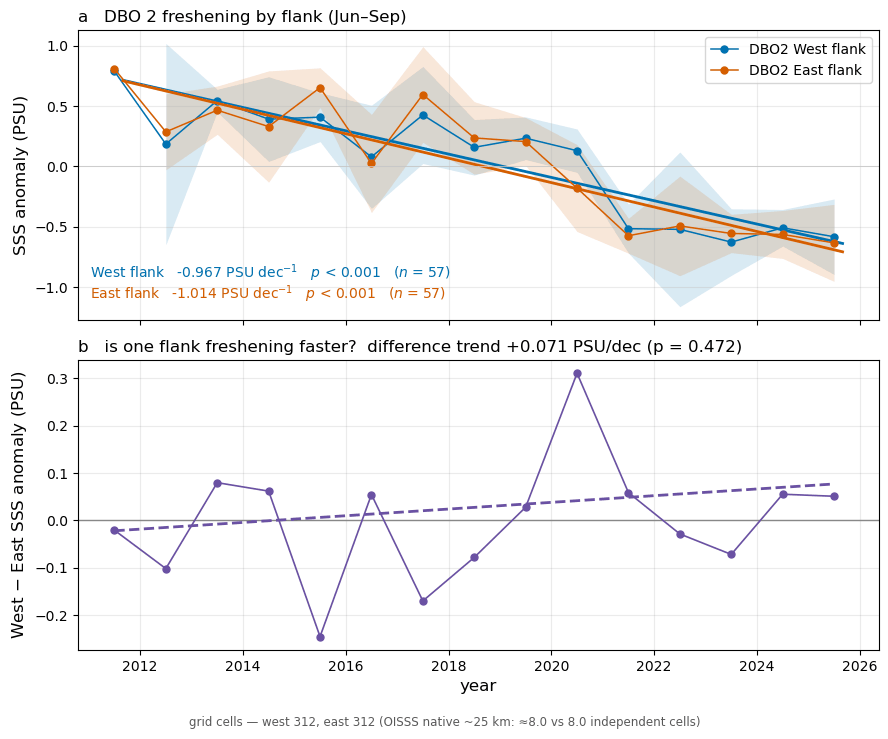


mean West−East SSS anomaly: -0.000 PSU  (negative = West fresher)


In [17]:
# DBO2 freshening: west vs east flank (same −169.36 split as the CDOM analysis)
lat_c   = lats2d[j0:j1+1, i0:i1+1]
lon36_c = lon360_2d[j0:j1+1, i0:i1+1]
SPLIT360 = 360 - 169.36                       # 190.64
inlat = (lat_c >= 64.481828) & (lat_c <= 65.107747)
MW = inlat & (lon36_c >= 360-170.865176) & (lon36_c <  SPLIT360)
ME = inlat & (lon36_c >= SPLIT360)           & (lon36_c <= 360-167.859549)

# sampling note — printed AND stamped under the figure (see fig.text below)
cells_note = (f'grid cells — west {MW.sum()}, east {ME.sum()} '
              f'(OISSS native ~25 km: ≈{MW.sum()*16/625:.1f} vs '
              f'{ME.sum()*16/625:.1f} independent cells)')
print(cells_note)

def _anom(mask):
    ser = sss.where(xr.DataArray(mask, dims=("y", "x"))).mean(("y", "x"), skipna=True)
    s = pd.Series(np.asarray(ser.values, float), index=pd.to_datetime(sss.time.values))
    return s - s.groupby(s.index.month).transform("mean")

def _pfmt(p):
    """Italic p for the in-panel annotation: 'p < 0.001', never 'p = 0.000'."""
    if not np.isfinite(p):
        return '$p$ = n/a'
    return '$p$ < 0.001' if p < 0.001 else f'$p$ = {p:.3f}'

# column names are capitalised HERE so FLANKS, both[...] and the difference all agree
sw, se = _anom(MW), _anom(ME)
both = pd.concat([sw.rename('West'), se.rename('East')], axis=1).dropna()
both = both[both.index.month.isin(SEASON)]                # Jun–Sep, as elsewhere

FLANKS = [('West', '#0072B2'), ('East', '#D55E00')]
fig, (ax, ax2) = plt.subplots(2, 1, figsize=(9, 7.4), sharex=True)

fits = {}
for nm, col in FLANKS:
    s = both[nm]
    dec = s.index.year + (s.index.dayofyear - 1) / 365.25
    fit = ts_mk_ar1_xy(np.asarray(dec, float), s.values)
    fits[nm] = fit
    g = s.groupby(s.index.year); m_, se_ = g.mean(), g.sem()
    ax.fill_between(m_.index + .5, m_ - 1.96*se_, m_ + 1.96*se_, color=col, alpha=.15, lw=0)
    ax.plot(m_.index + .5, m_.values, 'o-', color=col, ms=5, lw=1.1,
            label=f'DBO2 {nm} flank')
    xx = np.array([np.nanmin(dec), np.nanmax(dec)])
    sig = np.isfinite(fit['p']) and fit['p'] < 0.05
    ax.plot(xx, fit['intercept'] + fit['slope']*xx, color=col,
            ls='-' if sig else (0, (4, 2)), lw=2 if sig else 1.2)
    print(f'{nm}: {fit["slope"]*10:+.3f} PSU/decade, p = {fit["p"]:.4f} (n = {fit["n"]})')

# per-flank slope / p / n ON the panel, colour-matched to each flank (house style)
for k, (nm, col) in enumerate(FLANKS):
    f = fits[nm]
    ax.text(0.015, 0.125 - 0.075 * k,
            f'{nm} flank   {f["slope"]*10:+.3f} PSU dec$^{{-1}}$   '
            f'{_pfmt(f["p"])}   ($n$ = {f["n"]})',
            transform=ax.transAxes, color=col, fontsize=10,
            va='bottom', ha='left', zorder=5)

ax.axhline(0, color='#c8c8c8', lw=.6)
ax.set_ylabel('SSS anomaly (PSU)', fontsize=12)
ax.set_title('a   DBO 2 freshening by flank (Jun–Sep)', fontsize=12, loc='left')
ax.legend(fontsize=10, loc='upper right'); ax.grid(alpha=.25)

d = (both['West'] - both['East'])
decd = d.index.year + (d.index.dayofyear - 1) / 365.25
fitd = ts_mk_ar1_xy(np.asarray(decd, float), d.values)
gd = d.groupby(d.index.year).mean()
ax2.axhline(0, color='#888888', lw=1)
ax2.plot(gd.index + .5, gd.values, 'o-', color='#6A51A3', ms=5, lw=1.2)
xx = np.array([gd.index.min(), gd.index.max()]) + .5
ax2.plot(xx, fitd['intercept'] + fitd['slope']*xx, '-' if fitd['p'] < .05 else '--',
         color='#6A51A3', lw=2)
ax2.set_ylabel('West $-$ East SSS anomaly (PSU)', fontsize=12)
ax2.set_xlabel('year', fontsize=12)
ax2.set_title(f'b   is one flank freshening faster?  difference trend '
              f'{fitd["slope"]*10:+.3f} PSU/dec (p = {fitd["p"]:.3f})',
              fontsize=12, loc='left')
ax2.grid(alpha=.25)

# leave a strip at the bottom for the sampling note, then stamp it there
plt.tight_layout(rect=[0, 0.035, 1, 1])
fig.text(0.5, 0.008, cells_note, ha='center', va='bottom',
         fontsize=8.5, color='0.35')

fig.savefig(SYNOUT / 'dbo2_freshening_by_flank.png', dpi=300, bbox_inches='tight')
plt.show()
print(f'\nmean West−East SSS anomaly: {d.mean():+.3f} PSU  '
      f'(negative = West fresher)')
